<a href="https://colab.research.google.com/github/sriranjani-vs/Marine-Watch/blob/main/Marine_watch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Extracting the Zip fie

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/test.zip")
extract_dir = Path("/content/sonar_images")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("ZIP extracted to:", extract_dir)

ZIP extracted to: /content/sonar_images


Converted images to CSV


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage

# Change this to your extracted image folder
IMAGE_DIR = Path("/content/sonar_images")

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

print("Images found:", len(image_paths))

if not image_paths:
    raise ValueError(
        "No images found. Check IMAGE_DIR and the extracted folder."
    )

def extract_features(image_path):
    # Convert each sonar image to grayscale
    image = Image.open(image_path).convert("L")
    pixels = np.asarray(image, dtype=np.float32) / 255.0

    # Ignore completely black pixels where possible.
    # These often represent the area outside the sonar beam.
    valid = pixels > (5 / 255)

    if valid.sum() < 10:
        valid = np.ones(pixels.shape, dtype=bool)

    values = pixels[valid]

    # Basic intensity features
    features = {
        "image_name": image_path.name,
        "image_path": str(image_path),
        "width": image.width,
        "height": image.height,
        "mean_intensity": float(values.mean()),
        "std_intensity": float(values.std()),
        "min_intensity": float(values.min()),
        "max_intensity": float(values.max()),
        "median_intensity": float(np.median(values)),
        "p90_intensity": float(np.percentile(values, 90)),
        "p10_intensity": float(np.percentile(values, 10)),
        "valid_pixel_fraction": float(valid.mean()),
    }

    # Simple edge and texture measurements
    gy, gx = np.gradient(pixels)
    gradient = np.sqrt(gx**2 + gy**2)

    features["mean_gradient"] = float(gradient[valid].mean())
    features["std_gradient"] = float(gradient[valid].std())

    # Eight-bin brightness histogram
    hist, _ = np.histogram(
        values, bins=8, range=(0, 1), density=True
    )

    for i, value in enumerate(hist):
        features[f"histogram_bin_{i+1}"] = float(value)

    return features

rows = []

for path in image_paths:
    try:
        rows.append(extract_features(path))
    except Exception as error:
        print(f"Could not process {path.name}: {error}")

features_df = pd.DataFrame(rows)

output_path = Path("/content/marine_debris_features.csv")
features_df.to_csv(output_path, index=False)

print("\nCSV created:", output_path)
print("Images processed:", len(features_df))
print("CSV shape:", features_df.shape)

display(features_df.head())


Images found: 206

CSV created: /content/marine_debris_features.csv
Images processed: 206
CSV shape: (206, 22)


,image_name,image_path,width,height,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity,p90_intensity,...,mean_gradient,std_gradient,histogram_bin_1,histogram_bin_2,histogram_bin_3,histogram_bin_4,histogram_bin_5,histogram_bin_6,histogram_bin_7,histogram_bin_8
0,marine_marine-debris-aris3k-1009.png,/content/sonar_images/test/marine_marine-debri...,438,658,0.291083,0.143660,0.023529,1.0,0.266667,0.470588,...,0.048789,0.030251,0.573234,3.022834,2.664673,1.066264,0.394934,0.171174,0.078487,0.028399
1,marine_marine-debris-aris3k-1018.png,/content/sonar_images/test/marine_marine-debri...,438,658,0.410948,0.172087,0.023529,1.0,0.388235,0.658824,...,0.057873,0.037124,0.143561,1.344998,2.263624,2.037189,1.185901,0.669433,0.334509,0.020783
2,marine_marine-debris-aris3k-1043.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.310524,0.111319,0.023529,1.0,0.313726,0.447059,...,0.046742,0.029792,0.331651,2.075305,3.377200,1.866004,0.291149,0.045116,0.010691,0.002884
3,marine_marine-debris-aris3k-1046.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.323968,0.166086,0.023529,1.0,0.294118,0.568627,...,0.047989,0.032926,0.535466,2.492570,2.590826,1.231691,0.616511,0.357406,0.138180,0.037351
4,marine_marine-debris-aris3k-1052.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.358640,0.140858,0.023529,1.0,0.352941,0.541176,...,0.049950,0.033652,0.276506,1.574199,2.717740,2.221936,0.907303,0.229675,0.066787,0.005854


Downloading CSV


In [ ]:
from google.colab import files

files.download("/content/marine_debris_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Import Libraries


In [18]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

import joblib
import json
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
ANOMALY_RATE = 0.05

print("MarineWatch backend libraries loaded!")


MarineWatch backend libraries loaded!


Configure the dataset

In [19]:

IMAGE_DIR = Path("/content/sonar_images")
OUTPUT_DIR = Path("/content/marinewatch_output")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Image folder not found: {IMAGE_DIR}\n"
        "Upload or extract your images into this folder first."
    )

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

print("Images found:", len(image_paths))

if len(image_paths) == 0:
    raise ValueError("No supported image files were found.")


Images found: 206


Extract numerical features from every image

In [20]:

def extract_features(image_path):
    with Image.open(image_path) as image:
        gray = np.asarray(
            image.convert("L"), dtype=np.float32
        ) / 255.0

    # Ignore very dark pixels when calculating selected features.
    valid = gray > (5 / 255.0)
    pixels = gray[valid]

    # Use all pixels as a fallback if the image is almost entirely dark.
    if pixels.size == 0:
        pixels = gray.ravel()

    # Basic image intensity statistics.
    features = {
        "width": gray.shape[1],
        "height": gray.shape[0],
        "mean_intensity": float(pixels.mean()),
        "std_intensity": float(pixels.std()),
        "min_intensity": float(pixels.min()),
        "max_intensity": float(pixels.max()),
        "median_intensity": float(np.median(pixels)),
        "p90_intensity": float(np.percentile(pixels, 90)),
        "p10_intensity": float(np.percentile(pixels, 10)),
        "valid_pixel_fraction": float(valid.mean())
    }

    # Gradient-based texture features.
    grad_y, grad_x = np.gradient(gray)
    gradient = np.sqrt(grad_x**2 + grad_y**2)

    features["mean_gradient"] = float(gradient.mean())
    features["std_gradient"] = float(gradient.std())

    # Normalized histogram of grayscale intensity.
    hist, _ = np.histogram(
        gray.ravel(), bins=8, range=(0, 1)
    )
    hist = hist / max(hist.sum(), 1)

    for i, value in enumerate(hist, start=1):
        features[f"histogram_bin_{i}"] = float(value)

    return features


records = []
errors = []

for path in image_paths:
    try:
        features = extract_features(path)

        records.append({
            "image_name": path.name,
            "image_path": str(path),
            **features
        })

    except Exception as exc:
        errors.append({
            "image_path": str(path),
            "error": str(exc)
        })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("Feature extraction failed for every image.")

features_path = OUTPUT_DIR / "marine_debris_features.csv"
df.to_csv(features_path, index=False)

print("Successfully processed:", len(df))
print("Images with errors:", len(errors))
print("Feature count:", len([
    c for c in df.columns
    if c not in ["image_name", "image_path"]
]))
print("Features saved to:", features_path)

display(df.head())


Successfully processed: 206
Images with errors: 0
Feature count: 20
Features saved to: /content/marinewatch_output/marine_debris_features.csv


,image_name,image_path,width,height,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity,p90_intensity,...,mean_gradient,std_gradient,histogram_bin_1,histogram_bin_2,histogram_bin_3,histogram_bin_4,histogram_bin_5,histogram_bin_6,histogram_bin_7,histogram_bin_8
0,marine_marine-debris-aris3k-1009.png,/content/sonar_images/test/marine_marine-debri...,438,658,0.291083,0.143660,0.023529,1.0,0.266667,0.470588,...,0.026448,0.033145,0.504563,0.201652,0.177760,0.071130,0.026346,0.011419,0.005236,0.001894
1,marine_marine-debris-aris3k-1018.png,/content/sonar_images/test/marine_marine-debri...,438,658,0.410948,0.172087,0.023529,1.0,0.388235,0.658824,...,0.031563,0.040370,0.475351,0.089818,0.151164,0.136043,0.079194,0.044704,0.022338,0.001388
2,marine_marine-debris-aris3k-1043.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.310524,0.111319,0.023529,1.0,0.313726,0.447059,...,0.028338,0.032932,0.428569,0.154648,0.251663,0.139051,0.021696,0.003362,0.000797,0.000215
3,marine_marine-debris-aris3k-1046.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.323968,0.166086,0.023529,1.0,0.294118,0.568627,...,0.029122,0.035183,0.443726,0.185752,0.193074,0.091788,0.045944,0.026635,0.010298,0.002783
4,marine_marine-debris-aris3k-1052.png,/content/sonar_images/test/marine_marine-debri...,500,605,0.358640,0.140858,0.023529,1.0,0.352941,0.541176,...,0.030325,0.036297,0.424268,0.117345,0.202588,0.165630,0.067633,0.017121,0.004979,0.000436


Check data quality and image groups

In [21]:

df["image_group"] = np.where(
    df["image_name"].str.startswith("mine_sonar"),
    "mine_sonar",
    "marine_debris"
)

print("Image groups:")
print(df["image_group"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nImage dimensions:")
print(df.groupby("image_group")[["width", "height"]].agg(
    ["min", "max", "mean"]
).round(2))

print("\nSample image paths:")
display(df[["image_name", "image_path", "image_group"]].head(10))

if errors:
    pd.DataFrame(errors).to_csv(
        OUTPUT_DIR / "image_extraction_errors.csv",
        index=False
    )


Image groups:
image_group
marine_debris    188
mine_sonar        18
Name: count, dtype: int64

Missing values:
0

Image dimensions:
              width              height             
                min  max    mean    min  max    mean
image_group                                         
marine_debris   438  500  463.06    605  658  636.57
mine_sonar      416  416  416.00    416  416  416.00

Sample image paths:


,image_name,image_path,image_group
0,marine_marine-debris-aris3k-1009.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
1,marine_marine-debris-aris3k-1018.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
2,marine_marine-debris-aris3k-1043.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
3,marine_marine-debris-aris3k-1046.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
4,marine_marine-debris-aris3k-1052.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
5,marine_marine-debris-aris3k-1056.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
6,marine_marine-debris-aris3k-1077.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
7,marine_marine-debris-aris3k-1081.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
8,marine_marine-debris-aris3k-1084.png,/content/sonar_images/test/marine_marine-debri...,marine_debris
9,marine_marine-debris-aris3k-110.png,/content/sonar_images/test/marine_marine-debri...,marine_debris


Prepare features and perform PCA

Variance explained by 2 components: 80.81%


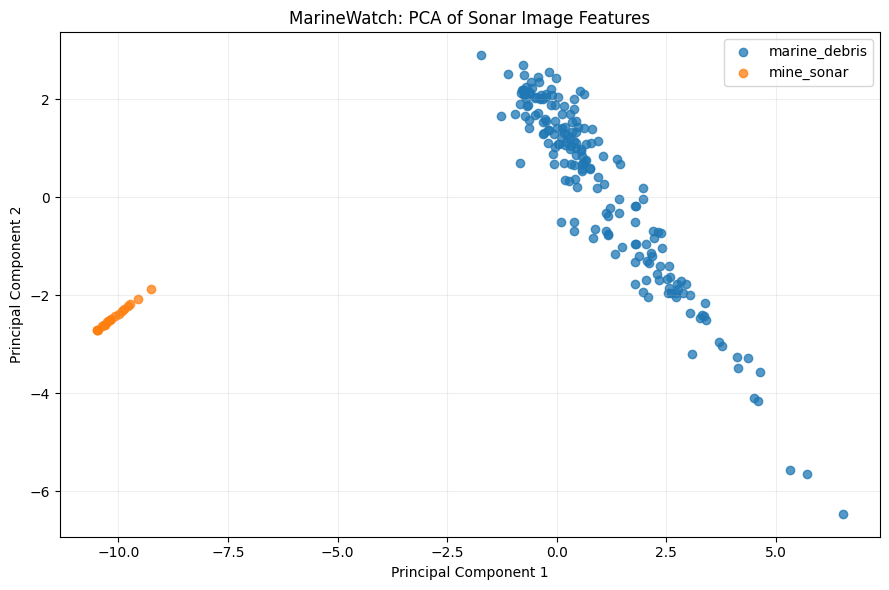

In [22]:

metadata_columns = {
    "image_name", "image_path", "image_group"
}

feature_cols = [
    col for col in df.columns
    if col not in metadata_columns
]

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)

# Impute any missing numerical values.
X = X.fillna(X.median()).fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA visualization.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

variance = pca.explained_variance_ratio_.sum() * 100

print(f"Variance explained by 2 components: {variance:.2f}%")

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

for group in df["image_group"].unique():
    mask = df["image_group"].to_numpy() == group
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=group,
        alpha=0.75
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("MarineWatch: PCA of Sonar Image Features")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_plot.png", dpi=150)
plt.show()


Detect potential anomalies

In [23]:

isolation_model = IsolationForest(
    contamination=ANOMALY_RATE,
    random_state=RANDOM_STATE
)

predictions = isolation_model.fit_predict(X_scaled)
scores = isolation_model.decision_function(X_scaled)

df["anomaly_score"] = scores
df["anomaly_label"] = np.where(
    predictions == -1,
    "Potential anomaly",
    "Normal-like"
)

print("Anomaly summary:")
print(df["anomaly_label"].value_counts())

print("\nAnomaly counts by image group:")
print(pd.crosstab(df["image_group"], df["anomaly_label"]))

print("\nPotential anomalies:")
display(
    df[df["anomaly_label"] == "Potential anomaly"][
        ["image_name", "image_group", "anomaly_score"]
    ].sort_values("anomaly_score")
)


Anomaly summary:
anomaly_label
Normal-like          195
Potential anomaly     11
Name: count, dtype: int64

Anomaly counts by image group:
anomaly_label  Normal-like  Potential anomaly
image_group                                  
marine_debris          185                  3
mine_sonar              10                  8

Potential anomalies:


,image_name,image_group,anomaly_score
191,mine_sonar86_jpg.rf.a7bc6bc21f73e1636afa72a097...,mine_sonar,-0.113881
198,mine_sonar92_jpg.rf.20b9433b2d27be0a4842ef5b43...,mine_sonar,-0.095550
59,marine_marine-debris-aris3k-1504.png,marine_debris,-0.062007
91,marine_marine-debris-aris3k-185.png,marine_debris,-0.041178
201,mine_sonar96_jpg.rf.a271f0c8428cb264f56e1a25e0...,mine_sonar,-0.037931
197,mine_sonar91_jpg.rf.1cc5cf29d0846c05146afe5260...,mine_sonar,-0.032220
195,mine_sonar8_jpg.rf.3efb1cf5aba7c2cefc21f1cab85...,mine_sonar,-0.026729
205,mine_sonar9_jpg.rf.b7e7154933ddb10f144a7b89327...,mine_sonar,-0.017850
202,mine_sonar97_jpg.rf.0af6e66998559e85188360e725...,mine_sonar,-0.003489
122,marine_marine-debris-aris3k-489.png,marine_debris,-0.002793


Display the flagged images

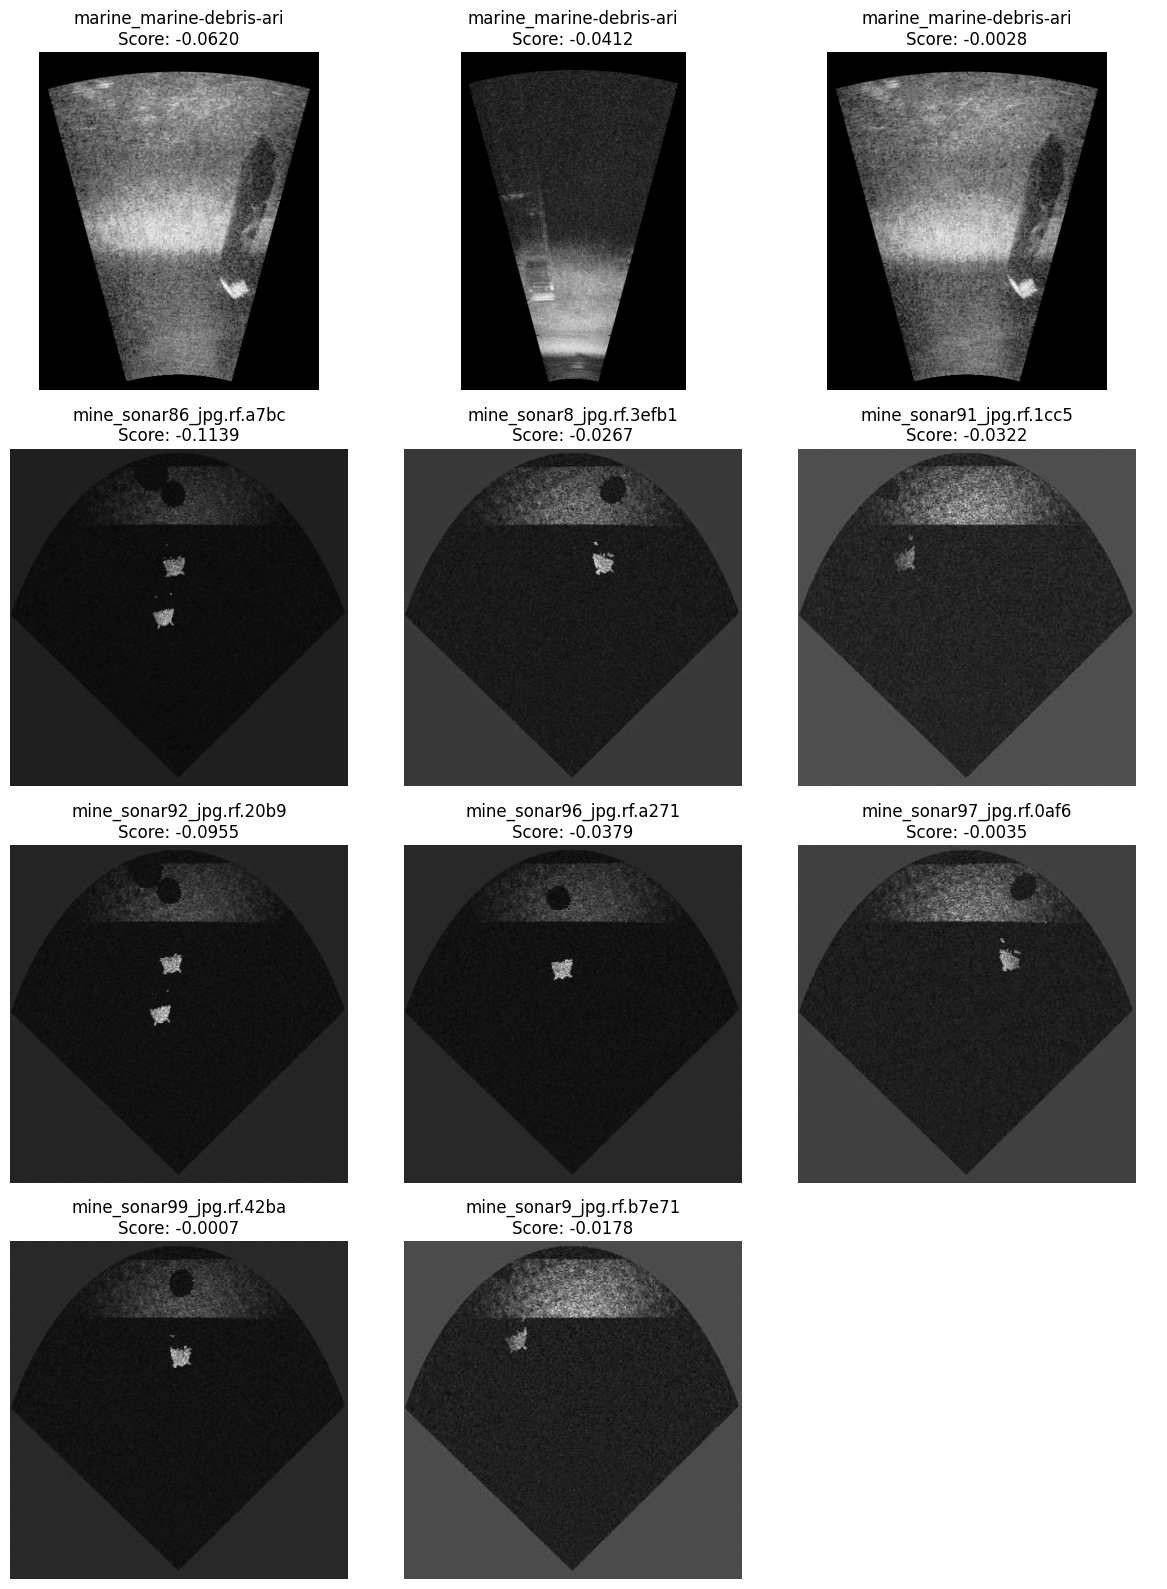

In [24]:

anomalies = df[df["anomaly_label"] == "Potential anomaly"]

if anomalies.empty:
    print("No anomalies were flagged.")
else:
    ncols = 3
    nrows = int(np.ceil(len(anomalies) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(12, 4 * nrows)
    )
    axes = np.atleast_1d(axes).ravel()

    for ax, (_, row) in zip(axes, anomalies.iterrows()):
        path = Path(row["image_path"])

        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("L"), cmap="gray")

            ax.set_title(
                f'{row["image_name"][:24]}\n'
                f'Score: {row["anomaly_score"]:.4f}'
            )
        except Exception:
            ax.set_title(f'Could not open: {row["image_name"][:20]}')

        ax.axis("off")

    for ax in axes[len(anomalies):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "anomaly_gallery.png", dpi=150)
    plt.show()


Save the results and trained models

In [25]:

results_path = OUTPUT_DIR / "marinewatch_results.csv"
df.to_csv(results_path, index=False)

joblib.dump(scaler, OUTPUT_DIR / "scaler.joblib")
joblib.dump(pca, OUTPUT_DIR / "pca.joblib")
joblib.dump(isolation_model, OUTPUT_DIR / "isolation_forest.joblib")

# Save model configuration for reproducibility.
config = {
    "feature_columns": feature_cols,
    "random_state": RANDOM_STATE,
    "contamination": ANOMALY_RATE,
    "pca_variance_explained_percent": round(float(variance), 2)
}

with open(OUTPUT_DIR / "model_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("MarineWatch processing completed!")
print("Output folder:", OUTPUT_DIR)
print("Results:", results_path)
print("Model files and plots saved.")


MarineWatch processing completed!
Output folder: /content/marinewatch_output
Results: /content/marinewatch_output/marinewatch_results.csv
Model files and plots saved.


Download your results

In [26]:

from google.colab import files

files.download(str(OUTPUT_DIR / "marinewatch_results.csv"))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>